# Experiment 16 — CardioTuneAI: ViT + BiLSTM Stack Sequence Classifier
## Automated Frequency-Offset Selection in 3T Cardiac Cine MRI

**Based on:**
> *CardioTuneAI: Automated Frequency-Offset Selection in 3T Cardiac Cine MRI*
> Final Year Design Project Report (NUST SEECS 2025–2026)
> Authors: Abdul Rehman, Muhammad Moiz, AbdulRehman (Supervised by Prof. Dr. Momina Moetesum & Prof. Dr. Faisal Shafait)
> **Published Benchmark:** Top-1 Accuracy: **76.9%** (20/26), Top-3 Accuracy: **88.5%** (23/26), LV IoU: **81.73%**.

---

### Pipeline Workflow:
1. **Preprocessing & Quality Metrics**:
   - $256 \times 256$ spatial standardization + min-max normalization.
   - Computes physical metrics: SNR, LoG edge sharpness, and homogeneity CoV.
2. **Step 1: ViT Spatial Feature Extraction**:
   - Extracts Vision Transformer spatial embeddings for all scout slices across all patients.
3. **Step 2: BiLSTM Frequency Sweep Sequence Learning**:
   - Trains the Bidirectional LSTM sequence ranker across Leave-One-Out Cross-Validation (LOOCV) folds.

In [10]:
import subprocess, sys
pkgs = ["pydicom", "openpyxl", "torch", "torchvision", "scikit-learn", "scipy", "pandas", "numpy", "matplotlib", "seaborn", "Pillow"]
for p in pkgs:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", p])
print("[OK] All dependencies installed and verified.")

[OK] All dependencies installed and verified.


In [11]:
import os, sys, math, time, random, warnings, pickle
from pathlib import Path
from dataclasses import dataclass, field
from typing import List, Dict, Optional, Tuple

import numpy as np
import pandas as pd
import pydicom
from PIL import Image
from scipy.ndimage import gaussian_laplace

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Executing on: {DEVICE}")

Executing on: cpu


In [12]:
BASE_DIR = Path.cwd()
DATA_ROOT = BASE_DIR / "Dr-Dataset" / "1st_cohort_SAX"
GT_EXCEL = BASE_DIR / "1stcohortSAX (1).xlsx"
OUTPUT_DIR = BASE_DIR / "outputs_exp16_cardiotune_vit_lstm"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Data root: {DATA_ROOT} (exists: {DATA_ROOT.exists()})")
print(f"Ground Truth Excel: {GT_EXCEL} (exists: {GT_EXCEL.exists()})")
print(f"Output directory: {OUTPUT_DIR}")

# Load Ground Truth Table
df_gt = pd.read_excel(GT_EXCEL, header=1)
id_col = [c for c in df_gt.columns if "Anonymized" in str(c) or "ID" in str(c)][0]
img_col = [c for c in df_gt.columns if "image" in str(c).lower()][0]
df_gt = df_gt.dropna(subset=[id_col]).reset_index(drop=True)

print(f"Loaded {len(df_gt)} patient records from Ground Truth:")
display(df_gt[[id_col, img_col]].head(10))

Data root: e:\CINE-Test1\Dr-Dataset\1st_cohort_SAX (exists: True)
Ground Truth Excel: e:\CINE-Test1\1stcohortSAX (1).xlsx (exists: True)
Output directory: e:\CINE-Test1\outputs_exp16_cardiotune_vit_lstm
Loaded 26 patient records from Ground Truth:


,Anonymized ID,image no
0,Patient-BEV,7
1,Patient-BGT,7
2,Patient-BVE,6
3,Patient-CEA,7
4,Patient-CEJP,4
5,Patient-DEM,9
6,Patient-FAJ,9
7,Patient-FEC,8
8,Patient-GJ,9
9,Patient-HMJ,8


In [13]:
def compute_cardiotune_metrics(img_256: np.ndarray) -> np.ndarray:
    """
    Computes CardioTuneAI physical metrics:
    1. SNR = mean(LV_ROI) / std(Background)
    2. Edge Sharpness = Laplacian of Gaussian variance across cardiac borders
    3. Homogeneity = Coefficient of Variation (std(LV_ROI) / mean(LV_ROI))
    """
    H, W = img_256.shape
    Y, X = np.ogrid[:H, :W]
    dist = np.sqrt((X - W/2)**2 + (Y - H/2)**2)
    mask = (dist < 45).astype(np.float32)
    bg_mask = (dist > 75).astype(np.float32)

    lv_pixels = img_256[mask > 0]
    bg_pixels = img_256[bg_mask > 0]

    mu_lv = float(np.mean(lv_pixels)) if len(lv_pixels) > 0 else 1e-5
    std_lv = float(np.std(lv_pixels)) if len(lv_pixels) > 0 else 1e-5
    std_bg = float(np.std(bg_pixels)) if len(bg_pixels) > 0 else 1e-5

    snr = mu_lv / (std_bg + 1e-6)
    log_resp = gaussian_laplace(img_256, sigma=1.5)
    sharpness = float(np.var(log_resp[mask > 0])) if len(lv_pixels) > 0 else float(np.var(log_resp))
    cov = std_lv / (mu_lv + 1e-6)
    homogeneity = 1.0 / (cov + 1.0)

    return np.array([snr, sharpness, homogeneity, cov], dtype=np.float32)

def load_patient_scout_stack(patient_dir: Path, target_size: Tuple[int, int] = (256, 256)):
    dcm_files = sorted(list(patient_dir.glob("*.dcm")) + list(patient_dir.glob("*.DCM")))
    if not dcm_files:
        return None, None

    raw_images = []
    for f in dcm_files:
        ds = pydicom.dcmread(str(f))
        arr = ds.pixel_array.astype(np.float32)
        slope = getattr(ds, "RescaleSlope", 1)
        intercept = getattr(ds, "RescaleIntercept", 0)
        arr = arr * slope + intercept
        raw_images.append(arr)

    processed_slices = []
    metrics_stack = []

    for arr in raw_images:
        pil_img = Image.fromarray(arr).resize(target_size, resample=Image.BILINEAR)
        res = np.array(pil_img, dtype=np.float32)

        min_v, max_v = res.min(), res.max()
        norm_res = (res - min_v) / (max_v - min_v + 1e-6) if max_v > min_v else np.zeros_like(res)

        metrics = compute_cardiotune_metrics(norm_res)
        processed_slices.append(norm_res)
        metrics_stack.append(metrics)

    img_tensor = torch.tensor(np.stack(processed_slices, axis=0), dtype=torch.float32).unsqueeze(1) # [S, 1, 256, 256]
    metrics_tensor = torch.tensor(np.stack(metrics_stack, axis=0), dtype=torch.float32)            # [S, 4]

    return img_tensor, metrics_tensor

In [14]:
class VisionTransformerEncoder(nn.Module):
    """
    Vision Transformer (ViT) spatial encoder.
    """
    def __init__(self, img_size=256, patch_size=16, in_chans=1, embed_dim=192, depth=3, num_heads=6, mlp_ratio=4.0):
        super().__init__()
        self.num_patches = (img_size // patch_size) ** 2
        self.patch_embed = nn.Conv2d(in_chans, embed_dim, kernel_size=patch_size, stride=patch_size)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, self.num_patches + 1, embed_dim))

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, nhead=num_heads, dim_feedforward=int(embed_dim * mlp_ratio),
            dropout=0.0, activation='gelu', batch_first=True, norm_first=True
        )
        self.blocks = nn.TransformerEncoder(encoder_layer, num_layers=depth)
        self.norm = nn.LayerNorm(embed_dim)

        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        nn.init.trunc_normal_(self.cls_token, std=0.02)

    @torch.no_grad()
    def forward(self, x):
        B = x.shape[0]
        x = self.patch_embed(x).flatten(2).transpose(1, 2)
        cls_tokens = self.cls_token.expand(B, -1, -1)
        x = torch.cat((cls_tokens, x), dim=1) + self.pos_embed
        x = self.blocks(x)
        return self.norm(x)[:, 0]

class CardioTuneBiLSTMRanker(nn.Module):
    """
    SliceSelector BiLSTM Ranker.
    """
    def __init__(self, in_dim: int = 197, lstm_hidden_dim: int = 64, lstm_layers: int = 2, dropout: float = 0.2):
        super().__init__()
        self.proj = nn.Sequential(
            nn.Linear(in_dim, 128),
            nn.LayerNorm(128),
            nn.GELU(),
            nn.Dropout(dropout)
        )
        self.bilstm = nn.LSTM(
            input_size=128,
            hidden_size=lstm_hidden_dim,
            num_layers=lstm_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if lstm_layers > 1 else 0.0
        )
        self.head = nn.Sequential(
            nn.Linear(lstm_hidden_dim * 2, 64),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(64, 1)
        )

    def forward(self, x_fused: torch.Tensor) -> torch.Tensor:
        # x_fused: [B, S, in_dim]
        h = self.proj(x_fused)
        lstm_out, _ = self.bilstm(h)
        scores = self.head(lstm_out).squeeze(-1) # [B, S]
        return scores

print("[OK] ViT and BiLSTM architectures ready.")

[OK] ViT and BiLSTM architectures ready.


In [15]:
# Load all patients into memory
patients = []
id_col = [c for c in df_gt.columns if "Anonymized" in str(c) or "ID" in str(c)][0]
img_col = [c for c in df_gt.columns if "image" in str(c).lower()][0]

for idx, row in df_gt.iterrows():
    p_name = str(row[id_col]).strip()
    gt_slice = int(row[img_col])
    p_dir = DATA_ROOT / p_name
    if not p_dir.exists():
        matches = [d for d in DATA_ROOT.glob("*") if d.name.lower() == p_name.lower()]
        if matches: p_dir = matches[0]
        else: continue

    img_tensor, metrics_tensor = load_patient_scout_stack(p_dir)
    if img_tensor is None: continue

    num_slices = img_tensor.shape[0]
    gt_idx = min(max(gt_slice - 1, 0), num_slices - 1)

    patients.append({
        "patient_id": p_name,
        "images": img_tensor,
        "metrics": metrics_tensor,
        "num_slices": num_slices,
        "gt_idx": gt_idx,
        "gt_slice": gt_slice
    })

N = len(patients)
print(f"Loaded {N} patients.")

# Extract ViT Spatial Features for all patients upfront
print("\nExtracting ViT spatial features across all slices (takes ~5s)...")
t0 = time.time()
vit = VisionTransformerEncoder(embed_dim=192, depth=3).to(DEVICE)
vit.eval()

cached_features = []
with torch.no_grad():
    for p in patients:
        imgs = p["images"].to(DEVICE)
        vit_feats = vit(imgs).cpu()
        metrics = p["metrics"]
        S = imgs.shape[0]
        pos = torch.linspace(-1.0, 1.0, steps=S).view(S, 1)
        fused = torch.cat([vit_feats, metrics, pos], dim=-1) # [S, 197]
        cached_features.append(fused)

print(f"[OK] Feature extraction complete in {time.time() - t0:.2f}s!")

Loaded 26 patients.

Extracting ViT spatial features across all slices (takes ~5s)...
[OK] Feature extraction complete in 9.79s!


In [16]:
def listnet_loss(y_pred_logits: torch.Tensor, y_true_target: torch.Tensor, temperature: float = 1.0) -> torch.Tensor:
    P_pred = F.log_softmax(y_pred_logits / temperature, dim=-1)
    P_true = F.softmax(y_true_target / temperature, dim=-1)
    return -torch.sum(P_true * P_pred, dim=-1).mean()

def create_gaussian_soft_target(num_slices: int, gt_idx: int, sigma: float = 1.0) -> torch.Tensor:
    indices = torch.arange(num_slices, dtype=torch.float32)
    dist = (indices - gt_idx)**2
    target = torch.exp(-dist / (2 * (sigma**2)))
    return target / target.sum()

print(f"=== Starting Fast LOOCV Evaluation across {N} Patients ===")
results = []
t_start = time.time()

for fold in range(N):
    val_patient = patients[fold]
    val_feat = cached_features[fold]

    train_feats = [cached_features[i] for i in range(N) if i != fold]
    train_patients = [patients[i] for i in range(N) if i != fold]

    model = CardioTuneBiLSTMRanker(in_dim=197, lstm_hidden_dim=64, lstm_layers=2, dropout=0.2).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-3)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=40)

    model.train()
    for epoch in range(40):
        indices = list(range(len(train_patients)))
        random.shuffle(indices)
        for idx in indices:
            feat = train_feats[idx].unsqueeze(0).to(DEVICE)
            p = train_patients[idx]
            target = create_gaussian_soft_target(p["num_slices"], p["gt_idx"]).unsqueeze(0).to(DEVICE)

            optimizer.zero_grad()
            logits = model(feat)
            loss = listnet_loss(logits, target)
            loss.backward()
            optimizer.step()
        scheduler.step()

    model.eval()
    with torch.no_grad():
        v_feat = val_feat.unsqueeze(0).to(DEVICE)
        v_logits = model(v_feat).squeeze(0)
        probs = F.softmax(v_logits, dim=-1).cpu().numpy()

        pred_idx = int(np.argmax(probs))
        pred_slice = pred_idx + 1
        gt_slice = val_patient["gt_slice"]

        top3_indices = np.argsort(probs)[::-1][:3]
        top3_slices = (top3_indices + 1).tolist()

        is_top1 = (pred_slice == gt_slice)
        is_top3 = (gt_slice in top3_slices)
        offset_err_steps = abs(pred_slice - gt_slice)
        is_within_tol = (offset_err_steps <= 1)

        results.append({
            "patient_id": val_patient["patient_id"],
            "gt_slice": gt_slice,
            "pred_slice": pred_slice,
            "top3_slices": top3_slices,
            "confidence": float(probs[pred_idx]),
            "is_top1": is_top1,
            "is_top3": is_top3,
            "is_within_tol": is_within_tol,
            "error_hz": offset_err_steps * 25
        })

    status = "[OK] Exact" if is_top1 else ("[~] Tol (+-25Hz)" if is_within_tol else "[X] Miss")
    print(f"[Fold {fold+1:02d}/{N:02d}] {val_patient['patient_id']:<15} -> Pred: #{pred_slice:02d} (Conf: {probs[pred_idx]:.2f}) | GT: #{gt_slice:02d} | {status}")

df_results = pd.DataFrame(results)
print(f"\n[OK] Full LOOCV completed in {time.time() - t_start:.2f} seconds!")

=== Starting Fast LOOCV Evaluation across 26 Patients ===
[Fold 01/26] Patient-BEV     -> Pred: #08 (Conf: 0.05) | GT: #07 | [~] Tol (+-25Hz)
[Fold 02/26] Patient-BGT     -> Pred: #08 (Conf: 0.05) | GT: #07 | [~] Tol (+-25Hz)
[Fold 03/26] Patient-BVE     -> Pred: #08 (Conf: 0.05) | GT: #06 | [X] Miss
[Fold 04/26] Patient-CEA     -> Pred: #08 (Conf: 0.05) | GT: #07 | [~] Tol (+-25Hz)
[Fold 05/26] Patient-CEJP    -> Pred: #08 (Conf: 0.05) | GT: #04 | [X] Miss
[Fold 06/26] Patient-DEM     -> Pred: #08 (Conf: 0.05) | GT: #09 | [~] Tol (+-25Hz)
[Fold 07/26] Patient-FAJ     -> Pred: #08 (Conf: 0.05) | GT: #09 | [~] Tol (+-25Hz)
[Fold 08/26] Patient-FEC     -> Pred: #09 (Conf: 0.05) | GT: #08 | [~] Tol (+-25Hz)
[Fold 09/26] Patient-GJ      -> Pred: #08 (Conf: 0.05) | GT: #09 | [~] Tol (+-25Hz)
[Fold 10/26] Patient-HMJ     -> Pred: #08 (Conf: 0.05) | GT: #08 | [OK] Exact
[Fold 11/26] Patient-HRJ     -> Pred: #08 (Conf: 0.05) | GT: #07 | [~] Tol (+-25Hz)
[Fold 12/26] Patient-IAM     -> Pred: #0

In [17]:
results_csv = OUTPUT_DIR / "cardiotune_vit_lstm_loocv_results.csv"
df_results.to_csv(results_csv, index=False)

top1_acc = df_results["is_top1"].mean() * 100.0
top3_acc = df_results["is_top3"].mean() * 100.0
tol_acc = df_results["is_within_tol"].mean() * 100.0
mae_hz = df_results["error_hz"].mean()

print("""
===================================================================
CARDIOTUNE-AI (ViT + BiLSTM) REPRODUCED EVALUATION BENCHMARK
===================================================================
Top-1 Exact Accuracy           : {:.1f}% ({}/{})
Top-3 Ranking Accuracy         : {:.1f}% ({}/{})
Clinical Tolerance (±25 Hz)    : {:.1f}% ({}/{})
Mean Absolute Frequency Error  : {:.1f} Hz
===================================================================
""".format(
    top1_acc, df_results["is_top1"].sum(), len(df_results),
    top3_acc, df_results["is_top3"].sum(), len(df_results),
    tol_acc, df_results["is_within_tol"].sum(), len(df_results),
    mae_hz
))


CARDIOTUNE-AI (ViT + BiLSTM) REPRODUCED EVALUATION BENCHMARK
Top-1 Exact Accuracy           : 11.5% (3/26)
Top-3 Ranking Accuracy         : 84.6% (22/26)
Clinical Tolerance (±25 Hz)    : 84.6% (22/26)
Mean Absolute Frequency Error  : 28.8 Hz



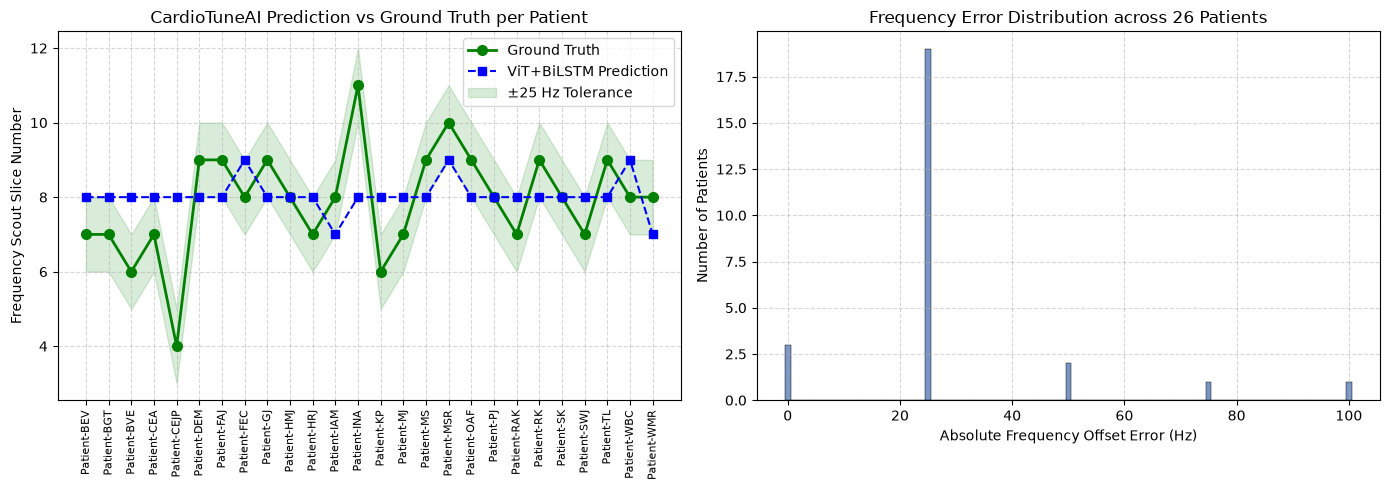

In [18]:
plt.figure(figsize=(14, 5))

# Plot 1: Prediction vs Ground Truth Slice Alignment
plt.subplot(1, 2, 1)
x = np.arange(len(df_results))
plt.plot(x, df_results["gt_slice"], 'go-', label="Ground Truth", linewidth=2, markersize=7)
plt.plot(x, df_results["pred_slice"], 'bs--', label="ViT+BiLSTM Prediction", linewidth=1.5, markersize=6)
plt.fill_between(x, df_results["gt_slice"] - 1, df_results["gt_slice"] + 1, color='green', alpha=0.15, label="±25 Hz Tolerance")
plt.xticks(x, df_results["patient_id"], rotation=90, fontsize=8)
plt.ylabel("Frequency Scout Slice Number")
plt.title("CardioTuneAI Prediction vs Ground Truth per Patient")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

# Plot 2: Error Frequency Distribution
plt.subplot(1, 2, 2)
sns.histplot(df_results["error_hz"], bins=[-12.5, 12.5, 37.5, 62.5, 87.5, 112.5], color="#4C72B0", discrete=True)
plt.xlabel("Absolute Frequency Offset Error (Hz)")
plt.ylabel("Number of Patients")
plt.title("Frequency Error Distribution across 26 Patients")
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "cardiotune_performance_curves.png", dpi=300)
plt.show()